# 03 — Train both wildlife classifiers on the v3 camera-controlled dataset
**Wildlife confidence calibration | v3 experiment | three paired seeds | resumable PyTorch training**

Run **Notebook 01 V3**, followed by **Notebook 02 V3** to verify the complete detected-only cache, before running this notebook. Notebook 02 must report `ready_for_final_training: true`. Place this notebook alongside the v3 notebooks in the same working directory, or set `PROJECT_ROOT` explicitly in Section 1.

The new inputs come from `wildlife_confidence_project_v3/` and `five_categories_detected_only_v3/`. V2 cleaned events and chose one photograph per event before assigning cameras and applying sampling caps. Notebook 01 V3 inherits those exact decisions and excludes every full-frame fallback without replacement; Notebook 02 V3 copies and verifies the retained animal crops. Original camera caps apply before these exclusions, and actual retained shares are reported. This notebook **does not** rebuild or resample that dataset. It verifies the frozen v3 decisions and processes only the five-class subset.

As in the original training plan, MobileNetV3-Large and EfficientNet-B0 are trained independently with paired seeds 42, 123 and 2026: two classifier-head epochs, then up to ten fine-tuning epochs, selecting the lowest event-weighted validation NLL across both stages (head wins ties). `RUN_LIMIT=None` attempts all remaining runs; set `RUN_LIMIT=2` to run just the first pair in one session. Completed runs are verified and skipped; incomplete runs resume at the last completed epoch.

Outputs use `training_v3/`; existing prepared v3 data remain unchanged. Complete full
technical image preparation before running the training cell. No manual image review or approval is required.

The notebook exports **validation, calibration and policy logits only**. It does not fit temperatures, choose thresholds, evaluate test predictions, or reuse V1/V2 trained checkpoints. The first training run needs the specified pretrained ImageNet weights to be available in the Torch cache or downloadable with an internet connection. CPU training can be slow; no runtime estimate is asserted without a v3 benchmark.


**V3 scope:** full-frame fallbacks are excluded from training, validation, calibration, policy and test.
Detected crops may still contain incorrect regions or species; file integrity does not prove semantic quality.
We retain V2 camera assignments, so prior V2 test exposure remains a limitation. Original development
caps apply before exclusion; post-exclusion shares are reported. Coverage is conditional on detection.


## 1. Retain the training protocol for the detected-only V3 data
Keep the completed Notebook 01/02 v3 artifacts unchanged. This experiment uses a separate
`training_v3/` directory; it cannot resume V2 trained checkpoints or optimizer states.

- Retain both ImageNet-pretrained architectures and all paired seeds **42, 123, 2026**.
- Two head epochs at AdamW lr **0.001**, feature parameters/statistics frozen.
- Restore the best head; fine-tune all parameters at lr **0.0001** for at most ten epochs.
  Keep the original BatchNorm behavior: feature running statistics are frozen during head
  training and updated during fine-tuning. Dropout/stochastic-depth follow the original modes.
- Batch size **4**, weight decay **0.0001**, unweighted cross-entropy, training-only horizontal flips.
- Select the **lowest event-weighted validation NLL across both stages**. Head wins cross-stage ties;
  strict improvements retain the earliest epoch within each stage. Fine-tuning stops after three
  consecutive epochs without improving its best validation NLL.
- Also record **equal-camera validation NLL**. These are diagnostics, not post hoc alternatives
  for selecting a more favourable model. Neither weighting certifies new-camera performance.

**Limitation — No manual crop verification**

This training notebook does not perform manual crop verification. Notebook 02 provides an optional training-only review sample; describe any review actually completed separately. Automatic checks establish file
integrity and consistency with the frozen dataset, not whether a crop contains the labelled animal.
Possible crop-label mismatches, incorrect detector boxes and inadequate crops remain study limitations.
Notebook 03 does not read or require the optional quality-review CSV from Notebook 02.

Only validation selects checkpoints. Calibration/policy/test outcomes remain excluded. Pretraining
recipes and classifier heads differ, so the comparison does not isolate architecture causally.

**Limitation — BatchNorm with small batches**

Training uses a batch size of four. During fine-tuning, BatchNorm running statistics are updated from these small batches, which may introduce instability or variability in model performance. This potential effect has not been experimentally isolated.



In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, math, os, platform, random, sys, time, traceback
import numpy as np
import pandas as pd
from PIL import Image
import PIL
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms

# Use the same project root as Notebooks 01 v3 and 02 v3.
# If the notebooks live beside the wildlife_confidence_project_v3 folder, leave this None.
PROJECT_ROOT = None
# Example for a separate working directory:
# PROJECT_ROOT = Path.home() / "ml_project" / "wildlife_confidence_project_v3"
EXPERIMENT_ID = "five_categories_detected_only_v3"
if PROJECT_ROOT is None:
    candidates = [Path.cwd() / "wildlife_confidence_project_v3", Path.cwd()]
    found = [p.resolve() for p in candidates
             if (p / "data/prepared" / EXPERIMENT_ID / "subset_manifest.csv").is_file()]
    found = list(dict.fromkeys(found))
    if len(found) != 1:
        raise FileNotFoundError(
            "Cannot locate Notebook 02 v3's subset_manifest.csv. "
            "Run Notebooks 01 and 02 v3 in this working directory, or set PROJECT_ROOT."
        )
    ROOT = found[0]
else:
    ROOT = Path(PROJECT_ROOT).expanduser().resolve()

PREPARED = ROOT / "data/prepared"
EXP = PREPARED / EXPERIMENT_ID
PREP_REPORTS = ROOT / "reports" / EXPERIMENT_ID
TRAIN_ID = "training_v3"
OUT = ROOT / "models" / EXPERIMENT_ID / TRAIN_ID
REPORT = PREP_REPORTS / TRAIN_ID

# Create *only* v3 training output folders. Never write to the completed v1 project.
if not (EXP / "subset_manifest.csv").is_file():
    raise FileNotFoundError(f"Not a prepared v3 experiment: {EXP}")
for path in (OUT, REPORT):
    path.mkdir(parents=True, exist_ok=True)

# Operational controls do not change the frozen training method.
RUN_LIMIT = None  # Set to 2 for one paired seed, or None for all remaining planned runs.
DEVICE_PREFERENCE = "cpu"  # "auto" tries CUDA then falls back to CPU.
PROGRESS_EVERY = 100



def utc_now():
    return datetime.now(timezone.utc).isoformat()

def sha_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def json_text(value):
    return json.dumps(value, indent=2, sort_keys=True, ensure_ascii=False, allow_nan=False) + "\n"

def atomic_text(path, content):
    temporary = Path(str(path) + ".tmp")
    temporary.write_text(content, encoding="utf-8")
    temporary.replace(path)

def freeze_text(path, content):
    path = Path(path)
    if path.exists() and path.read_text(encoding="utf-8") != content:
        raise ValueError(f"Frozen file differs: {path}. Do not modify the protocol after results.")
    if not path.exists():
        atomic_text(path, content)

def atomic_torch_save(value, path):
    temporary = Path(str(path) + ".tmp")
    torch.save(value, temporary)
    temporary.replace(path)

def log_event(name, details):
    with (REPORT / "training_execution_log.jsonl").open("a", encoding="utf-8") as f:
        f.write(json.dumps({"time_utc": utc_now(), "event": name, "details": details}) + "\n")

print("v3 project:", ROOT)
print("Experiment:", EXPERIMENT_ID)
print("torch:", torch.__version__, "| torchvision:", torchvision.__version__)


v3 project: /home/fia/Schreibtisch/wildlife_confidence_project_v3
Experiment: five_categories_detected_only_v3
torch: 2.14.0+cu130 | torchvision: 0.29.0+cu130


## 2. Verify v3 dataset provenance, camera disjointness and all prepared images
**Stop before training if any check fails.** This gate requires V3's detected-only crop protocol, unchanged inherited V2 camera assignment, and frozen V3 selection rules, and a technically complete image cache. It verifies every cached 224 × 224 PNG (including held-out images for *technical integrity only*), and checks camera/event identity, source hashes, category order and inherited absolute development camera-count caps. It also requires that the selected events are exactly the V2 animal-crop subset in the original order, with unchanged labels, cameras and partitions. Post-exclusion camera shares need not remain below the original 20% cap.

The script does **not** inspect test-classifier predictions or choose a new sample. Missing/corrupt input files must be repaired through Notebook 02 V3 after restoring or repairing the original local V2 cache. No missing images are silently removed. This integrity gate does not perform manual crop verification. Technical readiness does not establish that every crop visually matches its category label; possible crop-label mismatches remain a study limitation.


In [2]:
required = [
    EXP / "protocol.json", EXP / "selection_protocol.json", EXP / "classes.json",
    EXP / "subset_manifest.csv", EXP / "training_ready_manifest.csv",
    PREPARED / "camera_split.json", PREPARED / "preparation_run.json",
    PREPARED / "image_manifest.csv", PREPARED / "excluded_sequences.csv",
    PREP_REPORTS / "readiness.json",
]
for path in required:
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing v3 file: {path}. Complete Notebook 02 v3 with PROCESS_SCOPE='all' first."
        )

protocol = json.loads((EXP / "protocol.json").read_text(encoding="utf-8"))
selection = json.loads((EXP / "selection_protocol.json").read_text(encoding="utf-8"))
classes_record = json.loads((EXP / "classes.json").read_text(encoding="utf-8"))
camera_record = json.loads((PREPARED / "camera_split.json").read_text(encoding="utf-8"))
preparation_record = json.loads((PREPARED / "preparation_run.json").read_text(encoding="utf-8"))
readiness = json.loads((PREP_REPORTS / "readiness.json").read_text(encoding="utf-8"))

if (protocol.get("pipeline_kind") != "megadetector_detected_only_single_v3"
        or protocol.get("protocol_version") != 3
        or protocol.get("experiment_id") != EXPERIMENT_ID):
    raise ValueError("Input protocol is not Notebook 02's MegaDetector-assisted v3 experiment.")
if (selection.get("selection_version") != 3
        or selection.get("experiment_id") != EXPERIMENT_ID):
    raise ValueError("Selection protocol is not the frozen Notebook 02 v3 selection.")
if (camera_record.get("protocol") != "camera_stratified_event_v2"
        or camera_record.get("experiment_id") != "five_categories_camera_balanced_v2"):
    raise ValueError("Camera assignment is not Notebook 01's v3 split.")
if (preparation_record.get("stage") != "01_event_first_camera_split_v2"
        or preparation_record.get("experiment_id") != "five_categories_camera_balanced_v2"):
    raise ValueError("Notebook 01 event-level preparation record is not v3.")
if protocol["classes"] != selection["classes"] or protocol["classes"] != classes_record["classes"]:
    raise ValueError("Inconsistent class lists in the frozen v3 files.")
if protocol["class_to_idx"] != selection["class_to_idx"] or protocol["class_to_idx"] != classes_record["class_to_idx"]:
    raise ValueError("Class-index mapping changed between v3 files.")
if camera_record["selected_classes"] != protocol["classes"]:
    raise ValueError("Notebook 01's original category decision differs from Notebook 02.")
if preparation_record["split_sha256"] != sha_file(PREPARED / "camera_split.json"):
    raise ValueError("Notebook 01's camera split hash differs from its own preparation record.")
if preparation_record["manifest_sha256"] != sha_file(PREPARED / "image_manifest.csv"):
    raise ValueError("Notebook 01 event manifest was modified.")
if camera_record["event_manifest_sha256"] != sha_file(PREPARED / "event_manifest_all_categories.csv"):
    raise ValueError("Notebook 01 all-category event list was modified.")

PROTOCOL_SHA = sha_file(EXP / "protocol.json")
SELECTION_SHA = sha_file(EXP / "selection_protocol.json")
CAMERA_SPLIT_SHA = sha_file(PREPARED / "camera_split.json")
SUBSET_SHA = sha_file(EXP / "subset_manifest.csv")
READY_MANIFEST_SHA = sha_file(EXP / "training_ready_manifest.csv")
if not readiness.get("ready_for_final_training"):
    raise ValueError("Notebook 02 v3 has not reported full technical readiness. Use PROCESS_SCOPE='all'.")
if readiness.get("protocol_sha256") != PROTOCOL_SHA or readiness.get("subset_sha256") != SUBSET_SHA:
    raise ValueError("Readiness does not match the frozen v3 protocol/subset.")
if readiness.get("cross_split_duplicate_rows") != 0:
    raise ValueError("Notebook 02 detected exact duplicates across splits.")
for name, expected in protocol["input_sha256"].items():
    relative = Path(name)
    if relative.is_absolute() or ".." in relative.parts:
        raise ValueError(f"Unsafe provenance path: {name}")
    path = PREPARED / relative
    if not path.is_file() or sha_file(path) != expected:
        raise ValueError(f"Frozen Notebook 01/02 source file differs: {path}")

CLASSES = classes_record["classes"]
CLASS_TO_IDX = classes_record["class_to_idx"]
if CLASSES != ["coyote", "deer", "fox", "rabbit", "skunk"]:
    raise ValueError("Unexpected five-category experiment scope")
if CLASS_TO_IDX != {name: i for i, name in enumerate(CLASSES)}:
    raise ValueError("Unexpected class-index order")

source_events = pd.read_csv(PREPARED / "image_manifest.csv", dtype=str, keep_default_na=False)
base_manifest = pd.read_csv(EXP / "subset_manifest.csv", dtype=str, keep_default_na=False)
manifest = pd.read_csv(EXP / "training_ready_manifest.csv", dtype=str, keep_default_na=False)
if (not source_events.image_id.is_unique or not source_events.seq_id.is_unique
        or not base_manifest.image_id.is_unique or not base_manifest.seq_id.is_unique):
    raise ValueError("Duplicate image or event IDs in the source/selected v3 manifest.")
if not set(["train", "validation", "calibration", "policy", "test"]).issubset(set(base_manifest.split)):
    raise ValueError("One or more predefined v3 splits are missing.")
if not set(base_manifest.columns).issubset(manifest.columns):
    raise ValueError("Ready-manifest columns differ from the selected v3 subset.")
if not manifest[base_manifest.columns].equals(base_manifest):
    raise ValueError("Ready manifest differs from the frozen v3 image selection or row order.")
if not base_manifest.image_id.isin(source_events.image_id).all():
    raise ValueError("Selected v3 subset contains images not in Notebook 01's event manifest.")
identity_columns = ["image_id", "file_name", "location", "seq_id", "category_id", "class_name", "split"]
from_source = source_events.set_index("image_id").loc[base_manifest.image_id, identity_columns[1:]]
from_subset = base_manifest.set_index("image_id")[identity_columns[1:]]
if not from_subset.equals(from_source):
    raise ValueError("Selected subset changed an event label, ID, camera, or split from Notebook 01.")
if not source_events.location.map(camera_record["assignments"]).eq(source_events.split).all():
    raise ValueError("Notebook 01's source manifest disagrees with frozen camera assignments.")
if not manifest.location.map(camera_record["assignments"]).eq(manifest.split).all():
    raise ValueError("v3 selected images disagree with frozen camera assignments.")

manifest["label"] = manifest.label.astype(int)
if (not manifest.image_id.is_unique or not manifest.seq_id.is_unique
        or not manifest.groupby("location").split.nunique().eq(1).all()
        or not manifest.label.eq(manifest.class_name.map(CLASS_TO_IDX)).all()):
    raise ValueError("Event/camera leakage, duplicate records, or incorrect class indices.")
excluded_sequences = pd.read_csv(PREPARED / "excluded_sequences.csv", dtype=str, keep_default_na=False)
if manifest.seq_id.isin(excluded_sequences.seq_id).any():
    raise ValueError("A v3-excluded ambiguous sequence entered the training-ready manifest.")
if len(manifest) != readiness["planned_images"] or len(manifest) != readiness["verified_images"]:
    raise ValueError("Notebook 02 readiness counts do not match the selected images.")

split_names = ["train", "validation", "calibration", "policy", "test"]
selected_split_sizes = manifest.groupby("split").size().reindex(split_names, fill_value=0)
selected_camera_counts = manifest.groupby("split").location.nunique().reindex(split_names, fill_value=0)
selected_class_counts = pd.crosstab(manifest.class_name, manifest.split).reindex(
    index=CLASSES, columns=split_names, fill_value=0)
for split in ("validation", "calibration", "policy"):
    budget = int(selection["evaluation_budgets"][split])
    if selected_split_sizes[split] != budget:
        raise ValueError(f"v3 {split} count does not meet the frozen {budget}-event budget.")
    # The 20% cap was applied to V2's original intended sample, before exclusion.
    # Filtering can increase a camera's SHARE, although it cannot increase its event COUNT.
    parent_budget = int(selection["parent_evaluation_budgets"][split])
    inherited_cap = math.floor(parent_budget * float(selection["max_evaluation_camera_share"]))
    camera_events = manifest.loc[manifest.split.eq(split)].groupby("location").size()
    if int(camera_events.max()) > inherited_cap:
        raise ValueError(f"V3 {split} exceeds the inherited absolute camera count cap.")
    if selected_class_counts[split].min() < int(selection["min_selected_evaluation_category_events"]):
        raise ValueError(f"v3 {split} lacks the declared minimum category support.")
if selected_split_sizes["test"] > int(selection["evaluation_budgets"]["test"]):
    raise ValueError("Test size exceeds the v3 selection's maximum budget.")
if (selected_split_sizes == 0).any() or (selected_class_counts == 0).any().any():
    raise ValueError("Selected v3 dataset has an empty split or category.")

# Validate the actual cache; this is technical integrity verification, NOT test evaluation.
for i, row in enumerate(manifest.itertuples(index=False), 1):
    path = (ROOT / row.cache_relative_path).resolve()
    if not path.is_relative_to(ROOT):
        raise ValueError(f"Cache path leaves v3 project for {row.image_id}.")
    if not path.is_file() or sha_file(path) != row.cache_sha256:
        raise ValueError(f"Missing/corrupt v3 cache for {row.image_id}; rerun Notebook 02 verification.")
    with Image.open(path) as picture:
        if picture.size != (224, 224) or picture.mode != "RGB" or picture.format != "PNG":
            raise ValueError(f"Unexpected cached image format: {row.image_id}.")
        picture.load()
    if i % 2000 == 0:
        print(f"Verified {i}/{len(manifest)} v3 cache files", flush=True)
for hash_column in ("source_sha256", "cache_sha256"):
    if manifest[hash_column].eq("").any() or manifest.groupby(hash_column).split.nunique().gt(1).any():
        raise ValueError(f"Missing hashes or cross-split exact duplicates: {hash_column}.")

# No manual crop verification was performed. The optional Notebook 02 review
# sheet is not read, hashed, or required; automatic image/dataset checks above remain mandatory.

train_frame = manifest.loc[manifest.split.eq("train")].reset_index(drop=True)
validation_frame = manifest.loc[manifest.split.eq("validation")].reset_index(drop=True)
print("Verified v3 train:", len(train_frame), "| validation:", len(validation_frame))
print("v3 split sizes:", selected_split_sizes.to_dict())
print("v3 cameras per split:", selected_camera_counts.to_dict())
print("Manual crop verification: not performed; crop-label mismatches remain a study limitation.")
print("No test predictions will be computed by this notebook.")


# V3-specific safeguard: the selected set must be EXACTLY V2's animal-crop subset.
# No retained fallback, top-up, changed camera assignment, label or replacement frame is allowed.
crop_plan_v3 = pd.read_csv(EXP / 'crop_plan.csv', dtype=str, keep_default_na=False)
parent_plan_v2 = pd.read_csv(PREPARED / 'v2_reference/crop_plan.csv', dtype=str, keep_default_na=False)
parent_base_v2 = pd.read_csv(PREPARED / 'v2_reference/subset_manifest.csv', dtype=str, keep_default_na=False)
parent_ordered_plan = parent_plan_v2.set_index('image_id').loc[parent_base_v2.image_id]
expected_crop_ids = parent_base_v2.loc[parent_ordered_plan['mode'].eq('animal_crop').to_numpy(), 'image_id'].tolist()
if (not crop_plan_v3.image_id.is_unique or not crop_plan_v3['mode'].eq('animal_crop').all()
        or crop_plan_v3.image_id.tolist() != expected_crop_ids
        or manifest.image_id.tolist() != expected_crop_ids):
    raise ValueError('V3 contains a fallback, replacement event, missing crop, or changed row order.')
original_rows = parent_base_v2.set_index('image_id').loc[expected_crop_ids]
for column in ['file_name','location','seq_id','category_id','class_name','label','split']:
    if manifest[column].astype(str).tolist() != original_rows[column].astype(str).tolist():
        raise ValueError(f'V3 changed inherited event identity: {column}')
if protocol['crop_rule'].get('no_detection') != 'exclude_event_no_replacement':
    raise ValueError('V3 must exclude no-detection events without replacement.')


Verified 2000/11323 v3 cache files
Verified 4000/11323 v3 cache files
Verified 6000/11323 v3 cache files
Verified 8000/11323 v3 cache files
Verified 10000/11323 v3 cache files
Verified v3 train: 4377 | validation: 1330
v3 split sizes: {'train': 4377, 'validation': 1330, 'calibration': 1352, 'policy': 1389, 'test': 2875}
v3 cameras per split: {'train': 64, 'validation': 13, 'calibration': 13, 'policy': 13, 'test': 28}
Manual crop verification: not performed; crop-label mismatches remain a study limitation.
No test predictions will be computed by this notebook.


## 3. Record the environment and freeze a **new** v3 training protocol
All six runs inherit the v3 subset, split, crop protocol, and their SHA-256 hashes. The filenames `training_v3/` prevent reuse of v1 weights or logits. `RUN_LIMIT` changes only the number of pending runs attempted during this invocation, not the planned experiment or checkpoint-selection rules.

Use CPU by default to match the optional Notebook 02 technical pilot. Setting `DEVICE_PREFERENCE="auto"` tests real CUDA forward/backward operations before selecting CUDA; a different backend/environment is a different frozen training context. Save epoch-boundary optimizer/RNG states to resume safely. As with any PyTorch experiment, deterministic settings do not guarantee cross-platform bitwise identical results.


In [3]:
if DEVICE_PREFERENCE not in {"auto", "cpu"}:
    raise ValueError("Unknown DEVICE_PREFERENCE")
device = torch.device("cpu")
device_description = platform.processor() or platform.machine()
if DEVICE_PREFERENCE == "auto" and torch.cuda.is_available():
    try:
        probe = nn.Conv2d(3,4,3).to("cuda")
        probe(torch.randn(2,3,16,16,device="cuda")).sum().backward()
        torch.cuda.synchronize()
        del probe
        device = torch.device("cuda")
        device_description = torch.cuda.get_device_name(0)
    except Exception as error:
        print("CUDA probe failed; CPU fallback:", type(error).__name__, str(error))
        torch.cuda.empty_cache()
if device.type == "cpu":
    torch.set_num_threads(min(4,max(1,torch.get_num_threads())))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
TRAIN_CFG = {
    "training_id": TRAIN_ID, "training_revision": 3, "experiment_id": EXPERIMENT_ID,
    "manual_crop_verification_performed": False,
    "dataset_design": "v3_exact_V2_animal_crop_subset_inherited_camera_assignments",
    "camera_split_sha256": CAMERA_SPLIT_SHA, "selection_protocol_sha256": SELECTION_SHA,
    "planned_seeds": [42,123,2026],
    "models": ["mobilenet_v3_large", "efficientnet_b0"],
    "pretrained_weights": {"mobilenet_v3_large": "IMAGENET1K_V2", "efficientnet_b0": "IMAGENET1K_V1"},
    "batch_size": 4, "head_epochs": 2, "finetune_max_epochs": 10,
    "head_learning_rate": 0.001, "finetune_learning_rate": 0.0001,
    "optimizer": "AdamW", "weight_decay": 0.0001,
    "loss": "unweighted_cross_entropy", "selection": "lowest_validation_NLL_across_head_and_finetune",
    "early_stopping_patience": 3, "improvement_min_delta": 0.0,
    "train_drop_last": True, "num_workers": 0,
    "augmentation": "training_only_horizontal_flip_p0.5",
    "head_stage_batchnorm": "feature_statistics_frozen", "finetune_batchnorm": "updated",
    "selection_metric": "validation_nll", "selection_weighting": "event",
    "selection_tie_rule": "head_before_finetune_then_earliest_epoch",
    "validation_diagnostics": ["event_nll", "equal_camera_nll"],
    "final_checkpoint_file": "best_selected.pt",
    "classes": CLASSES, "protocol_sha256": PROTOCOL_SHA, "subset_sha256": SUBSET_SHA,
    "ready_manifest_sha256": READY_MANIFEST_SHA,
    "device_backend": device.type, "device_description": device_description,
    "versions": {"python": sys.version.split()[0], "torch": str(torch.__version__),
        "torchvision": str(torchvision.__version__), "numpy": np.__version__,
        "pandas": pd.__version__, "pillow": PIL.__version__},
    "cpu_threads": torch.get_num_threads() if device.type == "cpu" else None,
    "deterministic_algorithms": "warn_only", "cudnn_benchmark": False,
}
freeze_text(REPORT/"training_protocol.json", json_text(TRAIN_CFG))
TRAIN_SHA = sha_file(REPORT/"training_protocol.json")
print("Backend:", device, "|", device_description)
print("v3 camera split SHA-256:", CAMERA_SPLIT_SHA)
print("v3 selection SHA-256:", SELECTION_SHA)
print("Training protocol SHA-256:", TRAIN_SHA)
print("Planned paired seeds:", TRAIN_CFG["planned_seeds"], "| pending-run limit this invocation:", RUN_LIMIT)
log_event("protocol_loaded", {"training_sha256": TRAIN_SHA, "run_limit": RUN_LIMIT})


Backend: cpu | x86_64
v3 camera split SHA-256: 5d65707544cdafe9ae2208ca745623e4b1713c13a5e363ba902800963510f9fb
v3 selection SHA-256: 256dbc23d26e2d35a7063eaf513bbbcc5b27daa555ebcb243871c280b5e8f213
Training protocol SHA-256: 89d3b763f7b3383edf741ac43a89cc0dafc475fbd50c82f041f2f7c3bf15ab74
Planned paired seeds: [42, 123, 2026] | pending-run limit this invocation: None


## 4. Load v3 images and construct pretrained classifiers
Data loaders read **only the verified v3 processed PNGs**. The training loader applies seeded shuffling, 50% horizontal flipping, ImageNet tensor normalization, and `drop_last=True`; validation and development-logit exports use every image without flipping or shuffling. Camera IDs and event IDs are not model features. No training loader contains calibration, policy or test images.

Pretrained `torchvision` MobileNetV3-Large **IMAGENET1K_V2** and EfficientNet-B0 **IMAGENET1K_V1** are rebuilt from scratch for every independent run (unless restoring that run's own v3 checkpoint). Their final linear layers are replaced with five outputs. Download of the original pretrained ImageNet weights may be needed once.


In [4]:
class WildlifeDataset(Dataset):
    def __init__(self, frame, training=False):
        self.frame = frame.reset_index(drop=True).copy()
        operations = [transforms.RandomHorizontalFlip(0.5)] if training else []
        operations += [transforms.ToTensor(), transforms.Normalize(
            [0.485,0.456,0.406], [0.229,0.224,0.225])]
        self.transform = transforms.Compose(operations)
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(ROOT/row.cache_relative_path) as picture:
            x = self.transform(picture.convert("RGB"))
        return x, int(row.label), row.image_id


def loader_for(frame, training=False, order_seed=0):
    return DataLoader(WildlifeDataset(frame, training=training),
        batch_size=TRAIN_CFG["batch_size"], shuffle=training,
        drop_last=training, num_workers=TRAIN_CFG["num_workers"],
        generator=torch.Generator().manual_seed(order_seed))


def build_model(name, pretrained=True):
    if name == "mobilenet_v3_large":
        weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V2 if pretrained else None
        model = models.mobilenet_v3_large(weights=weights)
    elif name == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        model = models.efficientnet_b0(weights=weights)
    else:
        raise ValueError(name)
    model.classifier[-1] = nn.Linear(model.classifier[-1].in_features,len(CLASSES))
    return model


def configure_phase(model, phase):
    for parameter in model.parameters():
        parameter.requires_grad_(phase == "finetune")
    if phase == "head":
        for parameter in model.classifier.parameters():
            parameter.requires_grad_(True)
    return torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
        lr=TRAIN_CFG["head_learning_rate" if phase == "head" else "finetune_learning_rate"],
        weight_decay=TRAIN_CFG["weight_decay"])


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)


## 5. Training and validation metrics
Training loss/accuracy are measured during augmented weight updates; validation scores are computed after each epoch using evaluation mode and untouched validation images. They need not match even without overfitting. **NLL** here is mean cross-entropy on correct class labels. **Macro-F1** averages the five class F1 scores with zero for undefined category scores.

Validation controls checkpoint choice, so its lowest NLL is a *development* result, not final unseen-camera performance. No calibration, policy or test metrics enter training or checkpoint selection. The v3 camera distribution is different; v1 training curves/results cannot be carried over.


In [5]:
def set_training_mode(model, phase):
    if phase not in ("head", "finetune"):
        raise ValueError(f"Unknown training phase: {phase}")
    model.train()
    if phase == "head":
        model.features.eval()  # Original behavior: freeze feature statistics during head training.
    # During fine-tuning BatchNorm statistics update, as in the original v3 recipe.


def run_epoch(model, frame, training, phase, order_seed, optimizer=None):
    loader = loader_for(frame, training=training, order_seed=order_seed)
    if len(loader) == 0:
        raise ValueError("No batches")
    if training and optimizer is None:
        raise ValueError("Training requires the current run's phase optimizer")
    if training:
        set_training_mode(model, phase)
    else:
        model.eval()
    criterion = nn.CrossEntropyLoss(reduction="none")
    loss_sum, total = 0.0, 0
    confusion = np.zeros((len(CLASSES), len(CLASSES)), dtype=np.int64)
    camera_for_id = frame.set_index("image_id").location.to_dict()
    camera_totals = {}  # Additive sums, never an unweighted average of batch means.
    started = time.perf_counter()
    for batch_index, (inputs, labels, ids) in enumerate(loader, 1):
        inputs, labels = inputs.to(device), labels.to(device)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(inputs)
            if logits.shape != (len(labels), len(CLASSES)) or not torch.isfinite(logits).all():
                raise ValueError("Unexpected or nonfinite classifier outputs")
            losses = criterion(logits, labels)
            loss = losses.mean()
            if not torch.isfinite(loss):
                raise ValueError("Nonfinite loss")
            if training:
                loss.backward()
                optimizer.step()
        nll = losses.detach().cpu().numpy()
        truth = labels.detach().cpu().numpy()
        prediction = logits.detach().argmax(1).cpu().numpy()
        loss_sum += float(nll.sum())
        np.add.at(confusion, (truth, prediction), 1)
        total += len(labels)
        for image_id, value, correct in zip(ids, nll, prediction == truth):
            camera = camera_for_id[image_id]
            bucket = camera_totals.setdefault(camera, [0.0, 0, 0])
            bucket[0] += float(value)
            bucket[1] += int(correct)
            bucket[2] += 1
        if training and batch_index % PROGRESS_EVERY == 0:
            print(f"  {batch_index}/{len(loader)} batches | {time.perf_counter()-started:.0f}s", flush=True)
    if device.type == "cuda":
        torch.cuda.synchronize()
    tp = np.diag(confusion).astype(float)
    denom = confusion.sum(axis=0) + confusion.sum(axis=1)
    f1 = np.divide(2*tp, denom, out=np.zeros_like(tp), where=denom > 0)
    return {"nll": loss_sum/total, "accuracy": float(tp.sum()/total),
            "macro_f1": float(f1.mean()), "observations": int(total),
            "equal_camera_nll": float(np.mean([s[0]/s[2] for s in camera_totals.values()])),
            "cameras": len(camera_totals), "seconds": float(time.perf_counter()-started)}


## 6. Save resumable v3 checkpoints with provenance
Each independent v3 run writes its own `best_head.pt`, `best_finetune.pt`, `best_selected.pt` and `last_resume.pt`. The resume file holds epoch-boundary optimizer moments, random-generator states, history and the **v3 training/selection/camera hashes**. An interrupted partial epoch is repeated. No v1 weights, pilot checkpoint or optimizer states are ever accepted.

Checkpoint loading uses `weights_only=True` for **project-created files**, never arbitrary downloaded pickle content. This is an epoch-level recovery mechanism, not a promise of resuming within a batch.


In [6]:
def cpu_weights(model):
    return {name:value.detach().cpu().clone() for name,value in model.state_dict().items()}


def rng_state():
    state = np.random.get_state()
    return {"python": random.getstate(), "torch": torch.get_rng_state(),
        "numpy": [state[0],state[1].tolist(),int(state[2]),int(state[3]),float(state[4])],
        "cuda": torch.cuda.get_rng_state_all() if device.type == "cuda" else []}


def restore_rng(state):
    random.setstate(state["python"])
    torch.set_rng_state(state["torch"].cpu())
    value=state["numpy"]
    np.random.set_state((value[0],np.asarray(value[1],dtype=np.uint32),value[2],value[3],value[4]))
    if device.type == "cuda" and state["cuda"]:
        torch.cuda.set_rng_state_all([x.cpu() for x in state["cuda"]])


def load_checkpoint(path, model_name, seed, phase=None):
    saved = torch.load(path,map_location="cpu",weights_only=True)
    if (saved.get("training_sha256") != TRAIN_SHA
            or saved.get("subset_sha256") != SUBSET_SHA
            or saved.get("protocol_sha256") != PROTOCOL_SHA
            or saved.get("camera_split_sha256") != CAMERA_SPLIT_SHA
            or saved.get("experiment_id") != EXPERIMENT_ID):
        raise ValueError(f"Checkpoint provenance mismatch: {path}")
    if (saved.get("selection_protocol_sha256") != SELECTION_SHA
            or saved.get("ready_manifest_sha256") != READY_MANIFEST_SHA
            or saved.get("training_id") != TRAIN_ID
            or saved.get("model_name") != model_name or saved.get("seed") != int(seed)
            or (phase is not None and saved.get("phase") != phase)):
        raise ValueError(f"Wrong training revision, run identity, or phase: {path}")
    if saved.get("classes") != CLASSES or saved.get("pilot_only",False):
        raise ValueError("Class mismatch or pilot checkpoint")
    return saved


def checkpoint_context(model_name,seed):
    return {"model_name":model_name,"seed":int(seed),"classes":CLASSES,
            "experiment_id":EXPERIMENT_ID, "training_id":TRAIN_ID,
            "ready_manifest_sha256":READY_MANIFEST_SHA, "camera_split_sha256":CAMERA_SPLIT_SHA,
            "selection_protocol_sha256":SELECTION_SHA,
            "training_sha256":TRAIN_SHA,"protocol_sha256":PROTOCOL_SHA,
            "subset_sha256":SUBSET_SHA,"pilot_only":False}


## 7. Export v3 development logits without evaluating test images
From the **selected head-or-fine-tuning checkpoint** of each completed run, export logits for `validation`, `calibration` and `policy`. Every file includes class order, labels, image/camera/sequence IDs and v3 checkpoint/protocol hashes. Existing exports are reused only when every relevant identity and hash agrees.

The forward passes are deterministic inference, not further training. No temperature, confidence-based acceptance threshold, calibration score or test prediction is calculated here. A separately updated **Notebook 04 v3** must consume these files; the completed v1 Notebook 04 must not be reused as-is.


In [7]:
DEVELOPMENT_SPLITS = ("validation", "calibration", "policy")


def verify_development_export(path, split, model_name, seed, checkpoint_sha):
    frame = manifest.loc[manifest.split.eq(split)].reset_index(drop=True)
    with np.load(path, allow_pickle=False) as saved:
        required = {"logits", "image_ids", "labels", "locations", "seq_ids", "class_names",
                    "model_name", "seed", "checkpoint_sha256", "training_sha256",
                    "subset_sha256", "protocol_sha256", "camera_split_sha256", "experiment_id"}
        if not required.issubset(saved.files):
            raise ValueError(f"Missing development export fields: {path}")
        if saved["logits"].shape != (len(frame), len(CLASSES)) or not np.isfinite(saved["logits"]).all():
            raise ValueError(f"Invalid development logits: {path}")
        expected = {"model_name":model_name, "seed":int(seed), "checkpoint_sha256":checkpoint_sha,
                    "training_sha256":TRAIN_SHA, "subset_sha256":SUBSET_SHA,
                    "protocol_sha256":PROTOCOL_SHA, "camera_split_sha256":CAMERA_SPLIT_SHA,
                    "experiment_id":EXPERIMENT_ID}
        for key, value in expected.items():
            if saved[key].item() != value:
                raise ValueError(f"Development export provenance differs ({key}): {path}")
        for key, column, dtype in [("image_ids","image_id",str), ("labels","label",np.int64),
                                    ("locations","location",str), ("seq_ids","seq_id",str)]:
            if not np.array_equal(saved[key], frame[column].to_numpy(dtype=dtype)):
                raise ValueError(f"Development export identity differs ({key}): {path}")
        if not np.array_equal(saved["class_names"], np.asarray(CLASSES)):
            raise ValueError(f"Development class order differs: {path}")
    return {"file":Path(path).name, "sha256":sha_file(path)}


def export_logits(model, model_name, seed, run_dir, checkpoint_sha):
    paths = {}
    model.eval()
    for split in DEVELOPMENT_SPLITS:
        frame = manifest.loc[manifest.split.eq(split)].reset_index(drop=True)
        destination = run_dir / (split + "_logits.npz")
        if not destination.exists():
            logits_parts, labels_parts, ids = [], [], []
            with torch.no_grad():
                for x, y, image_ids in loader_for(frame, training=False):
                    output = model(x.to(device)).detach().cpu().numpy()
                    if output.shape != (len(y), len(CLASSES)) or not np.isfinite(output).all():
                        raise ValueError("Unexpected or nonfinite exported logits")
                    logits_parts.append(output.astype(np.float32))
                    labels_parts.append(y.numpy())
                    ids.extend(image_ids)
            if not logits_parts or ids != frame.image_id.tolist():
                raise ValueError(f"Empty development export or changed order: {split}")
            temporary = Path(str(destination) + ".tmp")
            with temporary.open("wb") as output:
                np.savez_compressed(output, logits=np.concatenate(logits_parts),
                    labels=np.concatenate(labels_parts).astype(np.int64), image_ids=np.asarray(ids,dtype=str),
                    locations=frame.location.to_numpy(dtype=str), seq_ids=frame.seq_id.to_numpy(dtype=str),
                    class_names=np.asarray(CLASSES), model_name=np.asarray(model_name), seed=np.asarray(seed),
                    checkpoint_sha256=np.asarray(checkpoint_sha), training_sha256=np.asarray(TRAIN_SHA),
                    subset_sha256=np.asarray(SUBSET_SHA), protocol_sha256=np.asarray(PROTOCOL_SHA),
                    camera_split_sha256=np.asarray(CAMERA_SPLIT_SHA), experiment_id=np.asarray(EXPERIMENT_ID))
            temporary.replace(destination)
            print("Exported", split, len(frame), "development logit vectors", flush=True)
        paths[split] = verify_development_export(destination, split, model_name, seed, checkpoint_sha)
    return paths


## 8. Train the first pair, then any remaining seeds
**This is the expensive cell.** Default order is MobileNet seed 42, EfficientNet seed 42, then both seed 123 and both seed 2026. It reloads a completed run only after verifying the saved checkpoint and export hashes. Interrupted runs resume at their last completed epoch using their v3 optimizer/RNG state.

`RUN_LIMIT=None` processes all remaining runs. To do the first seed pair only, change it to `2` in Section 1 **before** executing the training cell. This is an operational limit, not a change to the six-run scientific plan. Failures are recorded and never counted as completed runs.


In [8]:
def select_final_checkpoint(run_dir, model_name, seed):
    candidates = []
    for order, phase in enumerate(("head", "finetune")):
        path = run_dir / f"best_{phase}.pt"
        candidate = load_checkpoint(path, model_name, seed, phase)
        loss = float(candidate["validation_metrics"]["nll"])
        if not math.isfinite(loss):
            raise ValueError(f"Nonfinite candidate validation NLL: {path}")
        candidates.append((loss, order, candidate, path))
    # Head wins cross-stage ties; within-stage strict improvement keeps the earliest epoch.
    _, _, winner, source = min(candidates, key=lambda item: (item[0], item[1]))
    source_sha = sha_file(source)
    destination = run_dir / "best_selected.pt"
    if destination.exists():
        selected = load_checkpoint(destination, model_name, seed, winner["phase"])
        if (selected.get("source_checkpoint_sha256") != source_sha
                or selected.get("epoch") != winner["epoch"]
                or selected.get("validation_metrics") != winner["validation_metrics"]):
            raise ValueError("Existing selected checkpoint differs from the fixed cross-stage selection.")
    else:
        selected = {**winner, "source_checkpoint_file":source.name,
                    "source_checkpoint_sha256":source_sha,
                    "selection_rule":TRAIN_CFG["selection"]}
        atomic_torch_save(selected, destination)
    candidate_files = {phase:{"file":f"best_{phase}.pt", "sha256":sha_file(run_dir/f"best_{phase}.pt")}
                       for phase in ("head", "finetune")}
    return selected, destination, candidate_files


def completed_run_record(run_dir, model_name, seed):
    path = run_dir / "completed.json"
    if not path.exists():
        return None
    record = json.loads(path.read_text(encoding="utf-8"))
    for key, value in checkpoint_context(model_name, seed).items():
        if record.get(key) != value:
            raise ValueError(f"Completed-run identity/provenance mismatch ({key}): {run_dir}")
    if (record.get("status") != "completed" or record.get("checkpoint_file") != "best_selected.pt"
            or record.get("selected_stage") not in ("head", "finetune")):
        raise ValueError("Run has no completed cross-stage selected checkpoint")
    if set(record.get("exports", {})) != set(DEVELOPMENT_SPLITS):
        raise ValueError("Completed run must contain validation, calibration, and policy exports")
    candidate_files = record.get("candidate_checkpoints", {})
    if set(candidate_files) != {"head", "finetune"}:
        raise ValueError("Missing head/fine-tuning checkpoint comparison")
    for phase, entry in candidate_files.items():
        candidate = run_dir / f"best_{phase}.pt"
        if entry.get("file") != candidate.name or not candidate.is_file() or sha_file(candidate) != entry.get("sha256"):
            raise ValueError(f"Candidate checkpoint missing/changed: {candidate}")
    selected_path = run_dir / record["checkpoint_file"]
    if not selected_path.is_file() or sha_file(selected_path) != record.get("checkpoint_sha256"):
        raise ValueError("Completed-run selected checkpoint missing/changed")
    selected = load_checkpoint(selected_path, model_name, seed)
    if (selected.get("phase") != record.get("selected_stage")
            or selected.get("epoch") != record.get("selected_epoch")
            or selected.get("validation_metrics") != record.get("validation_metrics")
            or selected.get("source_checkpoint_sha256") != candidate_files[record["selected_stage"]]["sha256"]):
        raise ValueError("Selected checkpoint metadata do not match the completed run")
    # Recheck that the recorded winner actually obeys the prespecified comparison.
    select_final_checkpoint(run_dir, model_name, seed)
    for split in DEVELOPMENT_SPLITS:
        entry = record["exports"][split]
        expected_name = split + "_logits.npz"
        exported = run_dir / expected_name
        if entry.get("file") != expected_name or not exported.is_file() or sha_file(exported) != entry.get("sha256"):
            raise ValueError(f"Completed-run development export missing/changed: {split}")
        verify_development_export(exported, split, model_name, seed, record["checkpoint_sha256"])
    return record


def train_one(model_name,seed):
    optimizer = None  # This run's optimizer only, never shared with other model runs.
    run_dir=OUT/f"{model_name}_seed{seed}"
    run_dir.mkdir(parents=True,exist_ok=True)
    existing=completed_run_record(run_dir, model_name, seed)
    if existing:
        print("Already complete:",model_name,seed,flush=True)
        return existing
    context=checkpoint_context(model_name,seed)
    seed_everything(seed)
    last_path=run_dir/"last_resume.pt"
    resume=load_checkpoint(last_path, model_name, seed) if last_path.exists() else None
    # Resumed weights replace initialization; otherwise load the actual specified pretraining.
    model=build_model(model_name,pretrained=resume is None).to(device)
    if resume:
        if resume["model_name"] != model_name or resume["seed"] != seed:
            raise ValueError("Wrong run identity in resume checkpoint")
        model.load_state_dict(resume["state_dict"],strict=True)
    history=list(resume["history"]) if resume else []
    n_parameters=sum(p.numel() for p in model.parameters())
    phase_schedule=[("head",TRAIN_CFG["head_epochs"]),("finetune",TRAIN_CFG["finetune_max_epochs"])]
    session_started=time.perf_counter()
    try:
        for phase_index,(phase,epochs) in enumerate(phase_schedule):
            if resume and phase_index < resume["phase_index"]:
                continue
            optimizer=configure_phase(model,phase)
            same_phase=resume is not None and phase_index == resume["phase_index"]
            if same_phase:
                optimizer.load_state_dict(resume["optimizer_state_dict"])
                best_nll=float(resume["best_nll"])
                bad_epochs=int(resume["bad_epochs"])
                start_epoch=epochs+1 if resume["phase_finished"] else int(resume["epoch"])+1
                restore_rng(resume["rng_state"])
                print(f"Resuming {model_name} seed {seed}: {phase}, next epoch {start_epoch}",flush=True)
            else:
                best_nll,bad_epochs,start_epoch=float("inf"),0,1
            best_path=run_dir/f"best_{phase}.pt"
            for epoch in range(start_epoch,epochs+1):
                print(f"{model_name} | seed {seed} | {phase} epoch {epoch}/{epochs}",flush=True)
                # Unique epoch seed controls batch order; augmentation/dropout use restored torch RNG.
                train_metrics=run_epoch(model,train_frame,True,phase,seed+phase_index*10000+epoch,optimizer=optimizer)
                val_metrics=run_epoch(model,validation_frame,False,phase,seed+999)
                if not all(torch.isfinite(p).all().item() for p in model.parameters()):
                    raise ValueError("Nonfinite model parameter")
                improved=val_metrics["nll"] < best_nll
                if improved:
                    best_nll=val_metrics["nll"]
                    bad_epochs=0
                    atomic_torch_save({**context,"state_dict":cpu_weights(model),"phase":phase,
                        "epoch":epoch,"validation_metrics":val_metrics},best_path)
                else:
                    bad_epochs+=1
                row={"phase":phase,"epoch":epoch,"model":model_name,"seed":seed,
                     "train_nll":train_metrics["nll"],"train_accuracy":train_metrics["accuracy"],
                     "train_observations":train_metrics["observations"],
                     "validation_nll":val_metrics["nll"],"validation_accuracy":val_metrics["accuracy"],
                     "validation_macro_f1":val_metrics["macro_f1"],
                     "validation_equal_camera_nll":val_metrics["equal_camera_nll"],
                     "validation_observations":val_metrics["observations"],
                     "train_seconds":train_metrics["seconds"],"validation_seconds":val_metrics["seconds"],
                     "selected_so_far":bool(improved),"bad_epochs":bad_epochs}
                history.append(row)
                early_stop=phase=="finetune" and bad_epochs>=TRAIN_CFG["early_stopping_patience"]
                phase_finished=epoch==epochs or early_stop
                atomic_torch_save({**context,"state_dict":cpu_weights(model),
                    "optimizer_state_dict":optimizer.state_dict(),"rng_state":rng_state(),
                    "phase_index":phase_index,"phase":phase,"epoch":epoch,
                    "phase_finished":bool(phase_finished),"best_nll":best_nll,
                    "bad_epochs":bad_epochs,"history":history},last_path)
                atomic_text(run_dir/"history.csv",pd.DataFrame(history).to_csv(index=False))
                log_event("epoch_complete",row)
                print(f"  train NLL={train_metrics['nll']:.4f} | val NLL={val_metrics['nll']:.4f} | "
                      f"val accuracy={val_metrics['accuracy']:.3f} | "
                      f"{(train_metrics['seconds']+val_metrics['seconds'])/60:.1f} min",flush=True)
                if early_stop:
                    print("Early stopping on validation NLL.",flush=True)
                    break
            if not best_path.exists():
                raise ValueError(f"No valid checkpoint for {phase}")
            # Restore the best head before fine-tuning; restore best fine-tune before export.
            chosen=load_checkpoint(best_path, model_name, seed, phase)
            model.load_state_dict(chosen["state_dict"],strict=True)
            # A fresh optimizer is created when entering the next phase.
        selected, final_path, candidate_files = select_final_checkpoint(run_dir, model_name, seed)
        model.load_state_dict(selected["state_dict"], strict=True)
        model.eval()
        final_sha = sha_file(final_path)
        exports = export_logits(model, model_name, seed, run_dir, final_sha)
        record = {**context, "status":"completed", "time_utc":utc_now(),
            "parameters":int(n_parameters), "checkpoint_file":final_path.name,
            "selected_stage":selected["phase"], "selected_epoch":int(selected["epoch"]),
            "validation_metrics":selected["validation_metrics"], "checkpoint_sha256":final_sha,
            "candidate_checkpoints":candidate_files,
            "exports":exports, "completed_head_epochs":sum(r["phase"]=="head" for r in history),
            "completed_finetune_epochs":sum(r["phase"]=="finetune" for r in history),
            "epoch_seconds_total":float(sum(r["train_seconds"]+r["validation_seconds"] for r in history)),
            "last_session_wall_seconds":float(time.perf_counter()-session_started)}
        atomic_text(run_dir/"completed.json",json_text(record))
        log_event("run_complete",record)
        return record
    finally:
        optimizer=None
        del model
        if device.type=="cuda":
            torch.cuda.empty_cache()

if RUN_LIMIT is not None and (not isinstance(RUN_LIMIT,int) or RUN_LIMIT<1):
    raise ValueError("RUN_LIMIT must be a positive integer or None")
attempted=0
for seed in TRAIN_CFG["planned_seeds"]:
    for model_name in TRAIN_CFG["models"]:
        run_dir=OUT/f"{model_name}_seed{seed}"
        if run_dir.exists() and completed_run_record(run_dir, model_name, seed):
            print("Skipping verified completed run:",model_name,seed,flush=True)
            continue
        if RUN_LIMIT is not None and attempted>=RUN_LIMIT:
            continue
        attempted+=1
        try:
            train_one(model_name,seed)
        except KeyboardInterrupt:
            log_event("interrupted",{"model":model_name,"seed":seed,"resume":"last completed epoch"})
            raise
        except Exception as error:
            details={"model":model_name,"seed":seed,"error":f"{type(error).__name__}: {error}",
                     "traceback":traceback.format_exc()}
            atomic_text(REPORT/f"{model_name}_seed{seed}_latest_error.json",json_text(details))
            log_event("run_failed",details)
            print("RUN FAILED:",details["error"],flush=True)
            print("The error is saved; this run is not marked completed.",flush=True)
print("Training pass finished. The next cells summarize actual completed runs.")


mobilenet_v3_large | seed 42 | head epoch 1/2


/home/fia/miniconda3/envs/ml/lib/python3.11/site-packages/torch/cuda/__init__.py:484: UserWarning: Found GPU0 NVIDIA GeForce MX250 which is of compute capability (CC) 6.1.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0 except {8.7}
- 8.6 which supports hardware CC >=8.6,<9.0 except {8.7}
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 12.0 which supports hardware CC >=12.0,<13.0
Your installed torch==2.14.0+cu130 does not include kernels for this GPU. Reinstall the same version against a CUDA build that does, e.g.:
  For CUDA 12.6 use pip install torch==2.14.0 --index-url https://download.pytorch.org/whl/cu126
  _warn_unsupported_code(d, device_cc, code_ccs)
/home/fia/miniconda3/envs/ml/lib/python3.11/site-packages/torch/cuda/__init__.py:602: UserWarning: 
NVIDIA GeForce MX250 with C

  100/1094 batches | 8s
  200/1094 batches | 16s
  300/1094 batches | 23s
  400/1094 batches | 30s
  500/1094 batches | 38s
  600/1094 batches | 45s
  700/1094 batches | 54s
  800/1094 batches | 63s
  900/1094 batches | 71s
  1000/1094 batches | 80s
  train NLL=0.3595 | val NLL=0.8444 | val accuracy=0.733 | 1.9 min
mobilenet_v3_large | seed 42 | head epoch 2/2
  100/1094 batches | 8s
  200/1094 batches | 16s
  300/1094 batches | 24s
  400/1094 batches | 32s
  500/1094 batches | 40s
  600/1094 batches | 48s
  700/1094 batches | 56s
  800/1094 batches | 65s
  900/1094 batches | 73s
  1000/1094 batches | 80s
  train NLL=0.2048 | val NLL=0.8678 | val accuracy=0.752 | 1.9 min
mobilenet_v3_large | seed 42 | finetune epoch 1/10
  100/1094 batches | 26s
  200/1094 batches | 52s
  300/1094 batches | 78s
  400/1094 batches | 104s
  500/1094 batches | 130s
  600/1094 batches | 156s
  700/1094 batches | 182s
  800/1094 batches | 207s
  900/1094 batches | 233s
  1000/1094 batches | 259s
  train NLL

## 9. Summarize actual runs and development learning curves
The table lists **all six planned model/seed combinations**, including incomplete and pending runs. Validation NLL selected checkpoints; validation accuracy/macro-F1 are descriptive. The learning curves show head training followed by fine-tuning, never test performance.


             model  seed    status  fine_epochs selected_stage  selected_epoch  validation_equal_camera_nll  validation_nll  validation_accuracy  validation_macro_f1  training_validation_minutes
mobilenet_v3_large    42 completed            5       finetune               2                     0.660170        0.483494             0.819549             0.776014                    27.277594
   efficientnet_b0    42 completed            4           head               1                     0.557166        0.485156             0.821053             0.730388                    34.391645
mobilenet_v3_large   123 completed            7       finetune               4                     0.627500        0.529621             0.833083             0.770976                    31.781310
   efficientnet_b0   123 completed            7           head               1                     0.599497        0.503995             0.806015             0.733627                    53.426888
mobilenet_v3_large  2026 

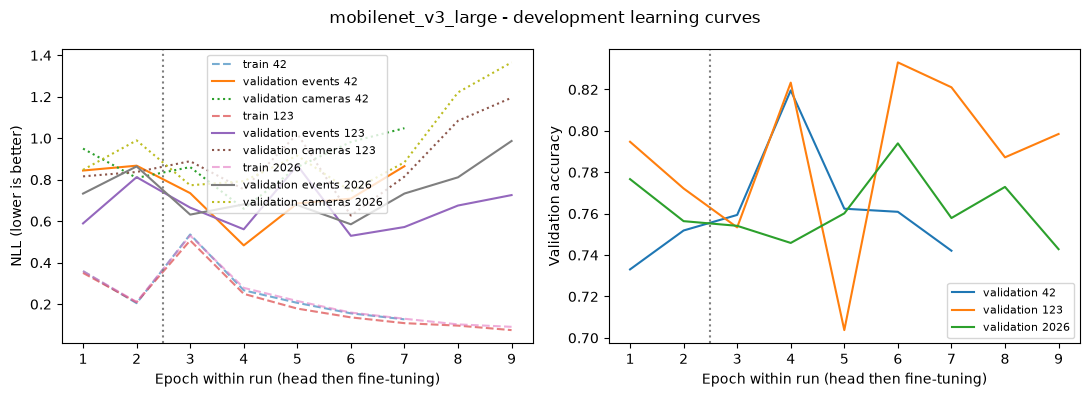

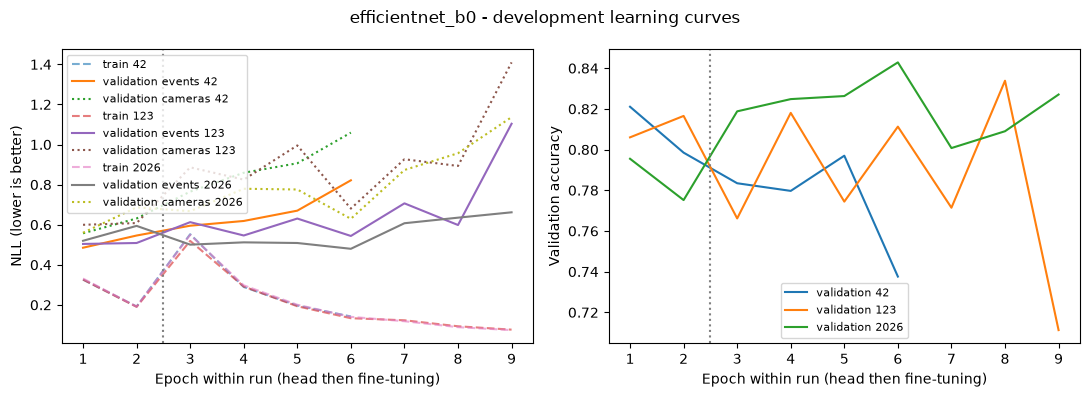

In [9]:
rows=[]
for seed in TRAIN_CFG["planned_seeds"]:
    for name in TRAIN_CFG["models"]:
        run_dir=OUT/f"{name}_seed{seed}"
        record=completed_run_record(run_dir, name, seed) if run_dir.exists() else None
        if record:
            rows.append({"model":name,"seed":seed,"status":"completed",
                "fine_epochs":record["completed_finetune_epochs"],
                "selected_stage":record["selected_stage"], "selected_epoch":record["selected_epoch"],
                "validation_equal_camera_nll":record["validation_metrics"]["equal_camera_nll"],
                "validation_nll":record["validation_metrics"]["nll"],
                "validation_accuracy":record["validation_metrics"]["accuracy"],
                "validation_macro_f1":record["validation_metrics"]["macro_f1"],
                "training_validation_minutes":record["epoch_seconds_total"]/60})
        else:
            rows.append({"model":name,"seed":seed,
                         "status":"incomplete" if (run_dir/"last_resume.pt").exists() else "pending"})
run_summary=pd.DataFrame(rows)
atomic_text(REPORT/"training_run_summary.csv",run_summary.to_csv(index=False))
print(run_summary.to_string(index=False))
completed_count=int(run_summary.status.eq("completed").sum())
print(f"Completed {completed_count}/{len(run_summary)} planned runs.")
print("These are validation metrics, not final test results.")
for name in TRAIN_CFG["models"]:
    histories=[]
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for seed in TRAIN_CFG["planned_seeds"]:
        path=OUT/f"{name}_seed{seed}"/"history.csv"
        if not path.exists():
            continue
        h=pd.read_csv(path)
        x=np.arange(1,len(h)+1)
        axes[0].plot(x,h.train_nll,linestyle="--",alpha=0.6,label=f"train {seed}")
        axes[0].plot(x,h.validation_nll,label=f"validation events {seed}")
        axes[0].plot(x,h.validation_equal_camera_nll,linestyle=":",label=f"validation cameras {seed}")
        axes[1].plot(x,h.validation_accuracy,label=f"validation {seed}")
        histories.append(h)
    for ax in axes:
        ax.axvline(TRAIN_CFG["head_epochs"]+0.5,color="gray",linestyle=":")
        ax.set_xlabel("Epoch within run (head then fine-tuning)")
        if histories:
            ax.legend(fontsize=8)
    axes[0].set_ylabel("NLL (lower is better)")
    axes[1].set_ylabel("Validation accuracy")
    fig.suptitle(name+" - development learning curves")
    fig.tight_layout()
    fig.savefig(REPORT/(name+"_learning_curves.png"),dpi=160,bbox_inches="tight")
    plt.show()


## 10. Record the v3 training methods and hand off to Notebook 04 v3
The notes and index are derived from the **actual v3 data counts and run results**, never copied from the old experiment. They identify all completed checkpoints and development-logit exports with hashes. If not all planned seeds finished, the index remains incomplete; never silently treat one seed as three.

These output files belong to `wildlife_confidence_project_v3/`. The v1 calibration/evaluation notebooks and report are not compatible until separately updated for this experiment.


In [10]:
index_records=[]
for seed in TRAIN_CFG["planned_seeds"]:
    for name in TRAIN_CFG["models"]:
        run_dir=OUT/f"{name}_seed{seed}"
        record=completed_run_record(run_dir, name, seed) if run_dir.exists() else None
        if record:
            index_records.append({"model":name,"seed":seed,
                "run_relative_path":str(run_dir.relative_to(ROOT)),
                "checkpoint_file":record["checkpoint_file"],"checkpoint_sha256":record["checkpoint_sha256"],
                "selected_stage":record["selected_stage"], "selected_epoch":record["selected_epoch"],
                "exports":record["exports"]})
training_index={"training_id":TRAIN_ID,"time_utc":utc_now(),"training_sha256":TRAIN_SHA,"protocol_sha256":PROTOCOL_SHA,
    "experiment_id":EXPERIMENT_ID,"camera_split_sha256":CAMERA_SPLIT_SHA,
    "selection_protocol_sha256":SELECTION_SHA,
    "subset_sha256":SUBSET_SHA,"classes":CLASSES,"planned_seeds":TRAIN_CFG["planned_seeds"],
    "all_planned_runs_complete":completed_count==len(run_summary),"completed_runs":index_records,
    "test_predictions_computed":False}
atomic_text(REPORT/"training_index.json",json_text(training_index))
notes=f"""# Corrected v3 training: {TRAIN_ID}
Updated: {utc_now()}

## Prepared data and readiness
Uses the frozen detected-only Notebook 01/02 V3 outputs for {EXPERIMENT_ID}. Notebook 01 excluded all full-frame fallbacks; this training notebook performs no further
splitting, sampling, cropping, exclusions or downloads. Subset SHA-256: {SUBSET_SHA}; input
protocol: {PROTOCOL_SHA}; camera split: {CAMERA_SPLIT_SHA}; selection: {SELECTION_SHA}.
Selected event counts: {selected_split_sizes.to_dict()}.
Selected camera counts: {selected_camera_counts.to_dict()}.
Selected category counts (metadata only, not test performance):
{selected_class_counts.to_string()}
Manual crop verification was not performed. The optional Notebook 02 review CSV is not read
or required. Automatic checks establish file integrity and frozen-dataset consistency, not whether
the selected detector crop contains the reference category. Possible crop-label mismatches,
incorrect boxes and inadequate crops remain study limitations. The selected input population
remains five known categories, one frame per eligible event. MegaDetector uses precomputed
MDv5a predictions with documented historical Caltech training overlap; camera holdout applies
to downstream fitting, not necessarily the pretrained detector.

## Training amendment, fixed before new evaluation
This is a new training revision, derived from the V2 recipe. It uses the new detected-only
V3 dataset, all three seeds {TRAIN_CFG['planned_seeds']}, both architectures and their
specified ImageNet pretrained weights. Batch size 4; unweighted cross-entropy; horizontal
flips in training only; AdamW weight decay 0.0001. Two head epochs at 0.001, then up to ten
fine-tuning epochs at 0.0001, with a fresh optimizer. All classifier-module parameters train
during the head stage; feature parameters and feature statistics are frozen then.
During fine-tuning all parameters are trainable and BatchNorm running statistics are updated,
matching the original V2 training behavior. Dropout/stochastic-depth follow the original training modes.

**Limitation — BatchNorm with small batches**

Training uses a batch size of four. During fine-tuning, BatchNorm running statistics are updated from these small batches, which may introduce instability or variability in model performance. This potential effect has not been experimentally isolated.
Early stopping: three fine-tuning epochs without a strict improvement in event-weighted
validation NLL. Final selection compares best_head.pt with best_finetune.pt on that same
metric; a cross-stage tie retains the head. Within-stage ties retain the earliest epoch.
The selected weights are copied to best_selected.pt, whose stage/epoch, candidate hashes
and source checkpoint hash are recorded. All development logits come from that exact file.
Equal-camera validation NLL is recorded each epoch as an additional diagnostic;
they do not change selection after seeing results. No calibration/policy/test performance
selects models or training settings. Test input integrity checks are not test evaluation.
The two architectures have different heads and pretraining recipes; this is not a causal
architecture-only comparison. Training drop_last=True omits a changing incomplete last batch;
validation and exports use every row without augmentation. Same prepared inputs/normalization
are used in training and downstream inference. One split and three training seeds do not
measure uncertainty across refitted datasets or new deployment cameras.

## Actual execution and provenance
Completed {completed_count}/{len(run_summary)} runs. Pending/failed runs remain visible in
training_run_summary.csv. Backend: {device}; versions: {TRAIN_CFG['versions']}.
Protocol SHA-256: {TRAIN_SHA}. Resume is at completed epoch boundaries with optimizer and
RNG state; older training_v2 runs are not resumed by training_v3. Completed runs
require all three verified development exports, matching run identity and candidate/selected
checkpoint hashes. Automatic input integrity and dataset-consistency checks do not overwrite the prepared data.
Files per run: history.csv, best_head.pt, best_finetune.pt, best_selected.pt, last_resume.pt,
completed.json, validation_logits.npz, calibration_logits.npz, policy_logits.npz. Preserve actual
weights and exports as well as their hashes. Do not claim success from the presence of a log.

## Evaluation handoff
Notebook 04 must read reports/{EXPERIMENT_ID}/{TRAIN_ID}/training_index.json and load each
run's checkpoint_file (best_selected.pt); do not substitute best_finetune.pt or old v3 exports.
All six runs are retained. Temperature fitting and uncertainty-aware policy selection belong
to Notebook 04 and must precede final test inference. Calibration/policy camera concentration,
distribution shift and prior V1/V2 test inspection remain study limitations; this training revision
does not repair them. No final test predictions are produced here.
"""
atomic_text(REPORT/"TRAINING_METHODS_AND_STATUS.md",notes)
log_event("training_pass_documented",{"completed":completed_count,"planned":len(run_summary),
                                     "training_index":"training_index.json"})
print("Report notes:",REPORT/"TRAINING_METHODS_AND_STATUS.md")
print("Next-stage v3 index:",REPORT/"training_index.json")
if completed_count<len(run_summary):
    print("To continue the predefined seeds: set RUN_LIMIT=None and rerun section 8 onward.")
print("Next step: run the supplied Notebook 04 V3, then Notebook 05 V3.")


Report notes: /home/fia/Schreibtisch/wildlife_confidence_project_v3/reports/five_categories_detected_only_v3/training_v3/TRAINING_METHODS_AND_STATUS.md
Next-stage v3 index: /home/fia/Schreibtisch/wildlife_confidence_project_v3/reports/five_categories_detected_only_v3/training_v3/training_index.json
Next step: run the supplied Notebook 04 V3, then Notebook 05 V3.


## Troubleshooting and stopping rules
- **Not ready:** Notebook 02 v3 must have verified every retained animal crop and created `reports/five_categories_detected_only_v3/readiness.json` with `ready_for_final_training=true`. An incomplete or corrupt cache will fail the preflight gate.
- **Wrong dataset or protocol:** use only `wildlife_confidence_project_v3/five_categories_detected_only_v3`; do not point `PROJECT_ROOT` to the V1/V2 directory, reuse old results, or change a frozen selection/camera split.
- **Missing cache or bad hash:** finish/repair Notebook 02 v3; this notebook never silently discards, replaces or resamples images.
- **Interrupted training:** rerun the notebook under the same environment. Completed runs are verified/skipped; an incomplete run resumes from its latest full epoch. A partial epoch repeats.
- **Frozen training protocol mismatch:** restore the original environment/settings; a genuine pre-test amendment needs a new training ID/protocol. Do not mix optimizer states from different configurations.
- **Out of memory/poor learning:** report the issue and the development curves. Batch size, epoch schedule or optimizer changes are scientific amendments, not runtime toggles. No test results may be used to choose them.
- **Only the first seed pair finished:** that is a preliminary result. The full plan remains six independent runs.

The notebook does **not** answer whether temperature scaling generalizes across held-out cameras; that requires the supplied Notebook 04 V3, followed by Notebook 05 V3.

- **Prepared data:** Notebook 01 fixes the V2 crop-only subset without reassigning cameras; Notebook 02 copies existing crops.
  Complete that cache verification before starting training.
- **No manual crop verification:** no review CSV, manual decisions, or approval are required. Automatic file integrity does not certify crop-label agreement.
- **Final winner:** downstream inference must use `best_selected.pt` and the corrected training index.
  Do not assume the winner is fine-tuned; the head can legitimately win.

